# 01 · Dataset analysis

What the benchmark alerts look like, before any model sees them:

1. class and scenario mix,
2. how the key signals differ by typology, including the deliberate **look-alike** scenarios,
3. the **accuracy ceiling** (a supervised model trained on 10k separate alerts) and the **floor** (analyst rules),
4. which test alerts are **ambiguous by construction**.

Labels come from the scenario that generated each alert, never from rules applied to its features.

In [1]:
%matplotlib inline
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from nbutil import *
style()
pd.set_option("display.precision", 3)

from triage import baselines
from triage.schema import TYPOLOGIES
DATA = data_dir()
test = load_jsonl(DATA / "alerts_test.jsonl")
reference = load_jsonl(DATA / "alerts_reference.jsonl")
print(f"{len(test)} test alerts, {len(reference)} reference alerts from {DATA}")
print("transaction source:", sorted({a['provenance']['source'] for a in test}))

500 test alerts, 10000 reference alerts from data
transaction source: ['paysim']


## 1 · Class and scenario mix

In [2]:
def flat(alerts):
    rows = []
    for a in alerts:
        t, s = a["transaction"], a["signals"]
        rows.append({"typology": a["label"]["typology"], "scenario": a["label"]["scenario"].split("/")[1],
                     "type": t["type"], "amount": t["amount"], "drain_ratio": baselines.drain_ratio(t),
                     "pool": a["provenance"]["paysim_pool"], **s})
    return pd.DataFrame(rows)
df = flat(test)
mix = df.groupby(["typology", "scenario", "pool"]).size().rename("n").reset_index()
mix

,typology,scenario,pool,n
0,ACCOUNT_TAKEOVER,domestic_proxy,fraud,9
1,ACCOUNT_TAKEOVER,domestic_proxy,normal_large,16
2,ACCOUNT_TAKEOVER,foreign_login,fraud,32
3,ACCOUNT_TAKEOVER,session_hijack,fraud,7
4,ACCOUNT_TAKEOVER,session_hijack,normal_large,11
5,CASH_OUT_FRAUD,mule_known_session,fraud,61
6,CASH_OUT_FRAUD,mule_new_phone,fraud,14
7,NORMAL,large_payment,normal_large,19
8,NORMAL,new_customer,normal_any,12
9,NORMAL,new_device,normal_any,19


## 2 · Signals by typology

Each panel is one signal. Boxes show the middle 50% of alerts in that typology; whiskers the 5th–95th percentile.
Overlap between boxes is intended: real customers travel, change phones and make large payments.

/var/folders/zc/st9cfb017717dnwmp9_2vy380000gp/T/ipykernel_14638/2043067536.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True)
/var/folders/zc/st9cfb017717dnwmp9_2vy380000gp/T/ipykernel_14638/2043067536.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True)
/var/folders/zc/st9cfb017717dnwmp9_2vy380000gp/T/ipykernel_14638/2043067536.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, widths=0.55,

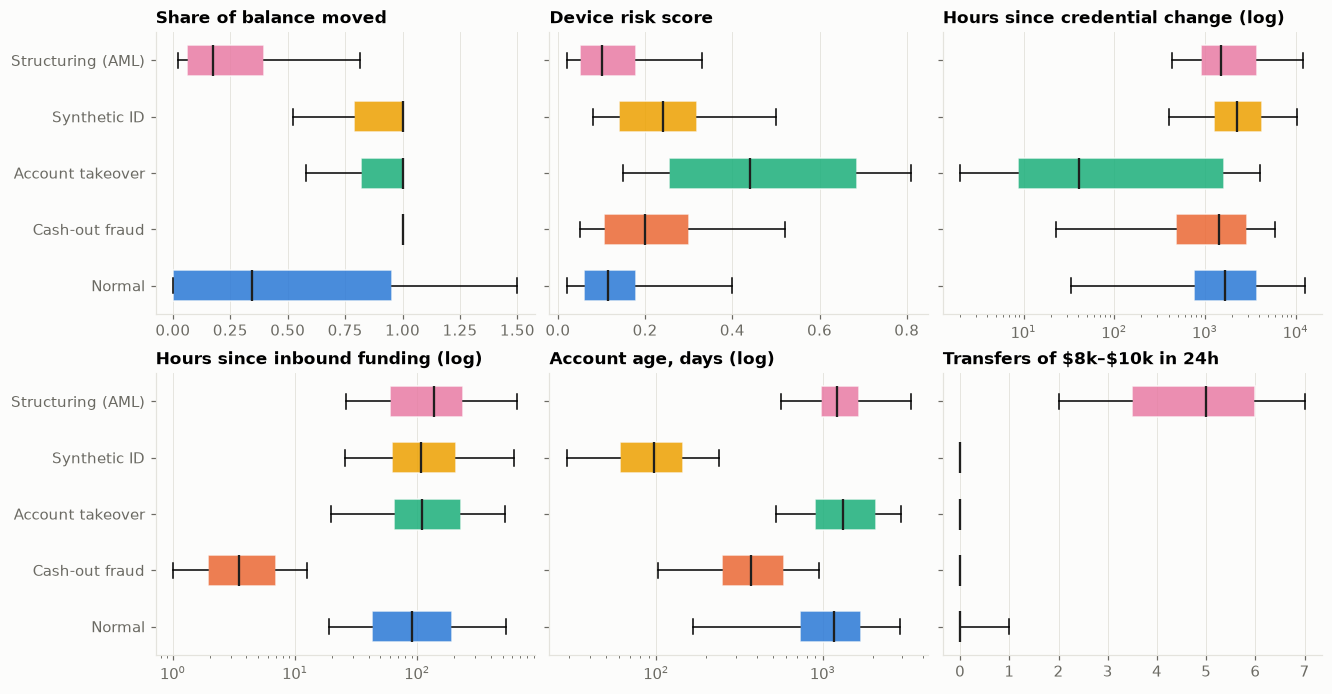

In [3]:
panels = [
    ("drain_ratio", "Share of balance moved", False),
    ("device_risk_score", "Device risk score", False),
    ("hours_since_credential_change", "Hours since credential change (log)", True),
    ("hours_since_inbound_funding", "Hours since inbound funding (log)", True),
    ("account_age_days", "Account age, days (log)", True),
    ("transfers_8k_to_10k_24h", "Transfers of \\$8k–\\$10k in 24h", False),
]
NICE = {"NORMAL": "Normal", "CASH_OUT_FRAUD": "Cash-out fraud", "ACCOUNT_TAKEOVER": "Account takeover",
        "SYNTHETIC_ID": "Synthetic ID", "STRUCTURING_AML": "Structuring (AML)"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), constrained_layout=True)
for ax, (col, title, log) in zip(axes.flat, panels):
    data = [df.loc[df.typology == t, col].clip(lower=0.1 if log else None) for t in TYPOLOGIES]
    bp = ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True)
    for patch, t in zip(bp["boxes"], TYPOLOGIES):
        patch.set(facecolor=TYPOLOGY_COLORS[t], alpha=0.85, edgecolor="#fcfcfb")
    for k in ("medians",):
        for line in bp[k]: line.set(color=INK, linewidth=1.5)
    ax.set_yticks(range(1, 6), [NICE[t] for t in TYPOLOGIES] if ax in axes[:, 0] else [""] * 5)
    if log: ax.set_xscale("log")
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
plt.show()

### Look-alike pairs

Each pair shares most of its signal distribution; only weak cues separate them. These pairs are where we expect
honest uncertainty from a good model, and where confident answers are most likely to be wrong.

In [4]:
pairs = [("NORMAL/new_device_large_payment", "ACCOUNT_TAKEOVER/domestic_proxy"),
         ("NORMAL/traveler_no_notice_large", "ACCOUNT_TAKEOVER/session_hijack"),
         ("NORMAL/payroll_batch", "STRUCTURING_AML/light"),
         ("NORMAL/new_customer", "SYNTHETIC_ID/sleeper"),
         ("CASH_OUT_FRAUD/mule_new_phone", "ACCOUNT_TAKEOVER/domestic_proxy")]
ref_df = flat(reference); ref_df["full"] = ref_df.typology + "/" + ref_df.scenario
cols = ["drain_ratio", "is_known_device", "device_risk_score", "hours_since_credential_change",
        "failed_login_attempts_24h", "hours_since_inbound_funding", "recipient_is_first_time",
        "account_age_days", "transfers_8k_to_10k_24h", "distinct_counterparties_24h"]
summary = ref_df.groupby("full")[cols].median()
pd.concat({f"{a.split('/')[1]} vs {b.split('/')[1]}": summary.loc[[a, b]] for a, b in pairs}).round(2)

drain_ratio  \
                                           full                                           
new_device_large_payment vs domestic_proxy NORMAL/new_device_large_payment         0.75   
                                           ACCOUNT_TAKEOVER/domestic_proxy         0.96   
traveler_no_notice_large vs session_hijack NORMAL/traveler_no_notice_large         0.70   
                                           ACCOUNT_TAKEOVER/session_hijack         0.96   
payroll_batch vs light                     NORMAL/payroll_batch                    0.23   
                                           STRUCTURING_AML/light                   0.19   
new_customer vs sleeper                    NORMAL/new_customer                     0.08   
                                           SYNTHETIC_ID/sleeper                    0.71   
mule_new_phone vs domestic_proxy           CASH_OUT_FRAUD/mule_new_phone           1.00   
                                           ACCOUNT_TAKEOVER/domestic_proxy         0.96   

                                                                            is_known_device  \
                                           full                                               
new_device_large_payment vs domestic_proxy NORMAL/new_device_large_payment              0.0   
                                           ACCOUNT_TAKEOVER/domestic_proxy              0.0   
traveler_no_notice_large vs session_hijack NORMAL/traveler_no_notice_large              1.0   
                                           ACCOUNT_TAKEOVER/session_hijack              1.0   
payroll_batch vs light                     NORMAL/payroll_batch                         1.0   
                                           STRUCTURING_AML/light                        1.0   
new_customer vs sleeper                    NORMAL/new_customer                          1.0   
                                           SYNTHETIC_ID/sleeper                         1.0   
mule_new_phone vs domestic_proxy           CASH_OUT_FRAUD/mule_new_phone                0.0   
                                           ACCOUNT_TAKEOVER/domestic_proxy              0.0   

                                                                            device_risk_score  \
                                           full                                                 
new_device_large_payment vs domestic_proxy NORMAL/new_device_large_payment               0.30   
                                           ACCOUNT_TAKEOVER/domestic_proxy               0.31   
traveler_no_notice_large vs session_hijack NORMAL/traveler_no_notice_large               0.26   
                                           ACCOUNT_TAKEOVER/session_hijack               0.32   
payroll_batch vs light                     NORMAL/payroll_batch                          0.09   
                                           STRUCTURING_AML/light                         0.10   
new_customer vs sleeper                    NORMAL/new_customer                           0.09   
                                           SYNTHETIC_ID/sleeper                          0.18   
mule_new_phone vs domestic_proxy           CASH_OUT_FRAUD/mule_new_phone                 0.32   
                                           ACCOUNT_TAKEOVER/domestic_proxy               0.31   

                                                                            hours_since_credential_change  \
                                           full                                                             
new_device_large_payment vs domestic_proxy NORMAL/new_device_large_payment                          21.25   
                                           ACCOUNT_TAKEOVER/domestic_proxy                          24.95   
traveler_no_notice_large vs session_hijack NORMAL/traveler_no_notice_large                        2554.90   
                                           ACCOUNT_TAKEOVER/session_hijack                        1978.30   
payroll_batch vs light 

## 3 · Ceiling and floor

**Ceiling:** gradient boosting trained on the reference split. The learning curve shows whether more training data would
raise it. A flat curve means the remaining errors are ambiguity in the data, not model capacity.

**Floor:** if-then rules an analyst would write from the same criteria text the models receive.

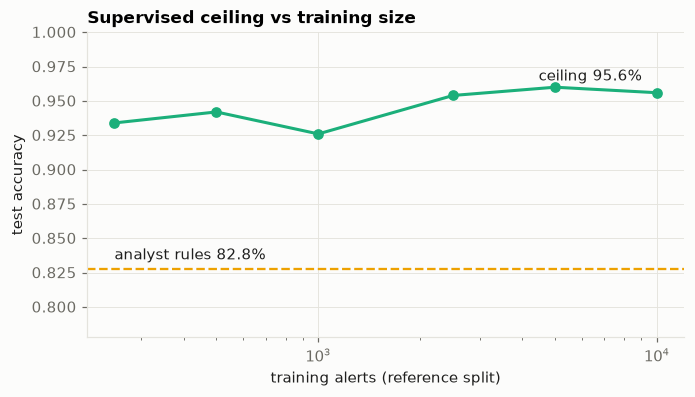

,train_size,accuracy,macro_f1
0,250,0.934,0.938
1,500,0.942,0.945
2,1000,0.926,0.932
3,2500,0.954,0.958
4,5000,0.960,0.963
5,10000,0.956,0.960


In [5]:
from sklearn.metrics import accuracy_score, f1_score
y_test = [a["label"]["typology"] for a in test]
sizes = [250, 500, 1000, 2500, 5000, len(reference)]
curve = []
for n in sizes:
    m = baselines.train_reference_model(reference[:n])
    pred = [max(p, key=p.get) for p in baselines.reference_predict(m, test)]
    curve.append({"train_size": n, "accuracy": accuracy_score(y_test, pred),
                  "macro_f1": f1_score(y_test, pred, average="macro")})
curve = pd.DataFrame(curve)
rules_pred = [baselines.rules_predict(a) for a in test]
floor = accuracy_score(y_test, rules_pred)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve.train_size, curve.accuracy, marker="o", markersize=6, color=MODEL_COLORS["reference_model"])
ax.axhline(floor, color=MODEL_COLORS["rules"], linestyle="--", linewidth=1.5)
ax.annotate(f"ceiling {curve.accuracy.iloc[-1]:.1%}", (curve.train_size.iloc[-1], curve.accuracy.iloc[-1]),
            textcoords="offset points", xytext=(-10, 8), ha="right", color=INK)
ax.annotate(f"analyst rules {floor:.1%}", (sizes[0], floor), textcoords="offset points", xytext=(0, 6), color=INK)
ax.set_xscale("log"); ax.set_ylim(min(floor, curve.accuracy.min()) - 0.05, 1.0)
ax.set_xlabel("training alerts (reference split)"); ax.set_ylabel("test accuracy")
ax.set_title("Supervised ceiling vs training size", loc="left")
plt.show()
curve

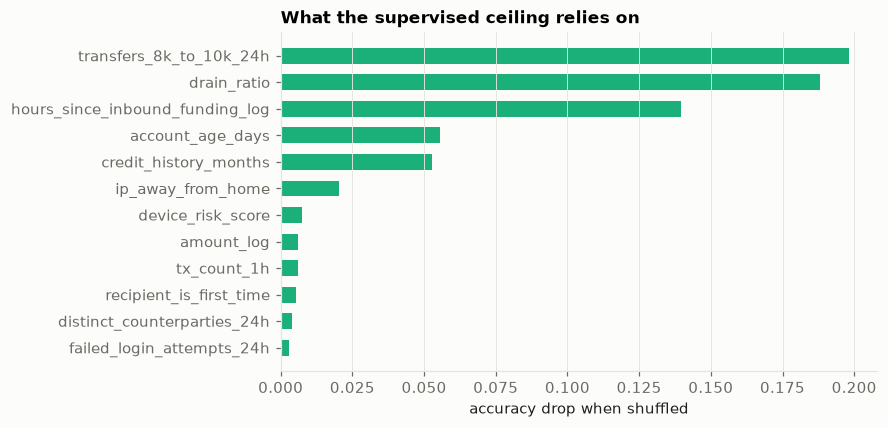

In [6]:
ref_model = baselines.train_reference_model(reference)
ref_probs = baselines.reference_predict(ref_model, test)
p_true = np.array([p[y] for p, y in zip(ref_probs, y_test)])
df["ref_p_true"] = p_true
df["difficulty"] = np.where(p_true >= 0.9, "clear", "ambiguous")

from sklearn.inspection import permutation_importance
X_test, y_idx = baselines.to_xy(test)
imp = permutation_importance(ref_model, X_test, y_idx, n_repeats=10, random_state=0, scoring="accuracy")
imp = pd.Series(imp.importances_mean, index=baselines.FEATURE_NAMES).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color=MODEL_COLORS["reference_model"], height=0.6)
ax.set_xlabel("accuracy drop when shuffled"); ax.grid(axis="y", visible=False)
ax.set_title("What the supervised ceiling relies on", loc="left")
plt.show()

## 4 · Ambiguous alerts

An alert is **ambiguous** when the supervised model gives its true class less than 0.9 probability. These alerts sit in
the overlap between scenarios. Zero-shot models should be *uncertain* here, not confidently right or wrong.

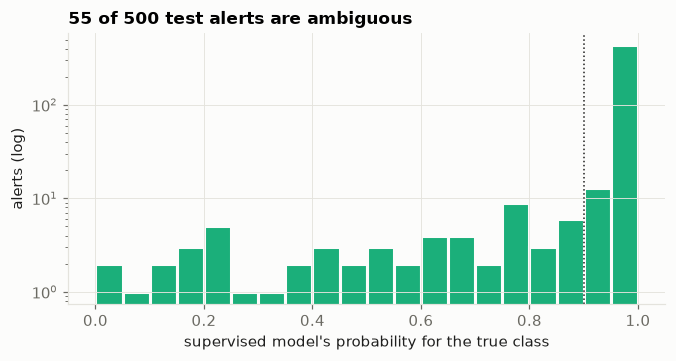

,n,ambiguous,median_p_true
full,,,
ACCOUNT_TAKEOVER/domestic_proxy,25,12,0.909
ACCOUNT_TAKEOVER/session_hijack,18,10,0.788
NORMAL/new_device_large_payment,10,10,0.295
STRUCTURING_AML/light,19,9,0.908
NORMAL/payroll_batch,6,6,0.331
NORMAL/traveler_no_notice_large,5,5,0.724
CASH_OUT_FRAUD/mule_known_session,61,2,0.998
STRUCTURING_AML/classic,56,1,0.998
CASH_OUT_FRAUD/mule_new_phone,14,0,0.998


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(p_true, bins=np.linspace(0, 1, 21), color=MODEL_COLORS["reference_model"], edgecolor="#fcfcfb", linewidth=2)
ax.axvline(0.9, color=INK, linewidth=1, linestyle=":")
ax.set_yscale("log"); ax.set_xlabel("supervised model's probability for the true class"); ax.set_ylabel("alerts (log)")
ax.set_title(f"{(p_true < 0.9).sum()} of {len(p_true)} test alerts are ambiguous", loc="left")
plt.show()
(df.assign(full=df.typology + "/" + df.scenario)
   .groupby("full").agg(n=("difficulty", "size"), ambiguous=("difficulty", lambda s: (s == "ambiguous").sum()),
                        median_p_true=("ref_p_true", "median"))
   .sort_values("ambiguous", ascending=False))

### Where the analyst rules go wrong

In [8]:
pd.crosstab(pd.Series(y_test, name="truth"), pd.Series(rules_pred, name="rules"))

rules,ACCOUNT_TAKEOVER,CASH_OUT_FRAUD,NORMAL,STRUCTURING_AML,SYNTHETIC_ID
truth,,,,,
ACCOUNT_TAKEOVER,40,0,35,0,0
CASH_OUT_FRAUD,1,67,7,0,0
NORMAL,10,1,185,3,1
STRUCTURING_AML,0,0,12,63,0
SYNTHETIC_ID,0,0,16,0,59
